<a href="https://colab.research.google.com/github/Kamya876/HW3-NLP/blob/main/hw3_part2_text_classification_bias_detective.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment Part 2 of 3: Text Classification Question -- Be a Bias Detective (5 points)

This assignment is split across **three notebooks** -- submit all three:

1. `hw3_part1_harms_vsd_case_study_empirical.ipynb` -- harms analysis, VSD case study, and written empirical-investigation questions
2. `hw3_part2_text_classification_bias_detective.ipynb` -- the coding question (5 points)
3. `hw3_part3_stakeholder_value_technical_reflection.ipynb` -- stakeholder analysis, value investigations, technical investigations, reflection

This file assumes you've already completed the Required Reading and Part 1 of 3. This is the coding question -- worth 5 points on its own.

### Names

Kamya Kanara

> **Google Colab setup:** This notebook is configured for Google Colab. Choose **Runtime → Change runtime type → T4 GPU** if available (CPU also works, but model inference may be slower). Run all cells from the top in order. The first setup cell installs a compatible Transformers 5.x and Hugging Face Hub 1.x combination so it matches the current Colab packages. The pretrained model downloads the first time D2 runs.


In [ ]:

%pip -q install --upgrade "transformers>=5,<6" "huggingface-hub>=1.23,<2"
print("Package setup complete. If imports fail after installation, use Runtime > Restart session, then choose Run all.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 41.4 MB/s eta 0:00:00
Package setup complete. If imports fail after installation, use Runtime > Restart session, then choose Run all.


In [ ]:

import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
print("Environment settings applied.")


Environment settings applied.


## Text Classification Question -- Be a Bias Detective (5 points)

In this section you'll build a small text classifier, then put on your detective hat and audit it -- along with a real pretrained model -- for exactly the kind of bias Sap et al. (2019) describe. By the end you will have literally looked inside your own model's "brain" and seen whether it learned to associate dialect with offensiveness.

This is meant to be a **mini** classifier -- one vectorizer, one model, nothing fancier. The point is to see the bias show up in something you actually built and ran predictions with, not to optimize model performance.

**Note:** the marker word-list approach in Part C is a coarse teaching simplification. The actual paper uses a proper probabilistic dialect/demographic language model (Blodgett et al., 2016) trained on geo-tagged tweets -- not a keyword list. Keep this distinction in mind when you write your interpretation at the end.

**Content warning:** the dataset below is a real hate-speech dataset and contains slurs and explicit profanity. That's inherent to the data, not a bug -- it's what the model needs to learn from to be meaningful. Skim rather than read closely if that's more comfortable; raw examples may appear when you inspect rows in Part A, though Part F is designed so nothing offensive appears there.

You will need internet access to download the dataset and (for Part D) a pretrained model. Run `pip install` for anything missing.

### Part A -- Load and inspect the data (0.5 pt)

We'll use the Davidson et al. (2017) hate speech dataset (DWMW17), one of the two main datasets Sap et al. (2019) audit directly (the other being Founta et al., 2018). Load it directly from GitHub.

In [ ]:
# Part A: Load the dataset
import pandas as pd

url = "https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv"

df = pd.read_csv(url)


print("Dataset shape (rows, columns):", df.shape)
display(df.head())


class_counts = df["class"].value_counts().sort_index()
print("\\nTweet counts by class (0 = hate speech, 1 = offensive language, 2 = neither):")
print(class_counts)

print("\\nClass proportions:")
print((df["class"].value_counts(normalize=True).sort_index() * 100).round(2).astype(str) + "%")
print("\\nIs the dataset balanced?", "No — the class counts differ substantially." if class_counts.max() / class_counts.min() > 1.5 else "Relatively balanced.")


Dataset shape (rows, columns): (24783, 7)


,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


\nTweet counts by class (0 = hate speech, 1 = offensive language, 2 = neither):
class
0     1430
1    19190
2     4163
Name: count, dtype: int64
\nClass proportions:
class
0     5.77%
1    77.43%
2     16.8%
Name: proportion, dtype: object
\nIs the dataset balanced? No — the class counts differ substantially.


Notes on the columns: `class` is 0 = hate speech, 1 = offensive language, 2 = neither. `tweet` is the raw tweet text.

Also note: this dataset is heavily imbalanced (very few "neither" tweets compared to "offensive" ones). Keep that in mind in Part B -- accuracy alone can look deceptively high on an imbalanced dataset.

### Part B -- Train a mini text classifier (1.5 pts)

Train a small TF-IDF + Logistic Regression classifier that predicts whether a tweet is offensive (`class` 0 or 1) vs. not (`class` 2). This mirrors -- at a small scale -- the kind of model the paper studies. Keep it to one vectorizer and one model; you do not need to try multiple algorithms.

Use the variable names below exactly (`X_train`, `X_test`, `y_train`, `y_test`, `vectorizer`, `clf`, `y_pred`) -- Part C reuses them.

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Original classes 0 and 1 are treated as offensive; class 2 is not offensive.
# Using 1 = offensive and 0 = not offensive so predict_proba()[:, 1] is P(offensive).
df = df.dropna(subset=["tweet", "class"]).copy()
df["binary_label"] = (df["class"] != 2).astype(int)

X = df["tweet"].astype(str)
y = df["binary_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 1),
    max_features=5000,
    min_df=2
)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

clf = LogisticRegression(max_iter=1000, class_weight=None, random_state=42)
clf.fit(X_train_vec, y_train)
y_pred = clf.predict(X_test_vec)

print(f"Training examples: {len(X_train):,}; test examples: {len(X_test):,}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\\nClassification report (0 = not offensive, 1 = offensive):")
print(classification_report(y_test, y_pred, target_names=["not offensive", "offensive"], zero_division=0))
print("Confusion matrix (rows = actual, columns = predicted; labels [0, 1]):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\\nInterpretation note: because the original data has many more offensive than 'neither' tweets, accuracy alone is not enough. Check precision, recall, and the confusion matrix too.")


Training examples: 19,826; test examples: 4,957
Test accuracy: 0.9417
\nClassification report (0 = not offensive, 1 = offensive):
               precision    recall  f1-score   support

not offensive       0.90      0.74      0.81       833
    offensive       0.95      0.98      0.97      4124

     accuracy                           0.94      4957
    macro avg       0.92      0.86      0.89      4957
 weighted avg       0.94      0.94      0.94      4957

Confusion matrix (rows = actual, columns = predicted; labels [0, 1]):
[[ 616  217]
 [  72 4052]]
\nInterpretation note: because the original data has many more offensive than 'neither' tweets, accuracy alone is not enough. Check precision, recall, and the confusion matrix too.


### Part C -- Measure the bias at two levels: the data, and your model (1.5 pts)

Write a heuristic function that flags whether a tweet likely contains AAE features, based on a small set of well-documented linguistic markers (e.g. "finna," "ain't," "tryna," "y'all," habitual "be," copula absence like "he going" instead of "he's going"). This is a rough proxy, not a real dialect classifier -- but it's enough to check for a correlation, the same kind of check the paper does at a larger scale.

You'll use this flag to check bias at **two levels**, mirroring the paper's two-part argument:

- **C1 -- Data-level bias:** is the *training data itself* skewed? (Do AAE-flagged tweets have a higher ground-truth offensive rate than non-flagged tweets, across the whole dataset?)
- **C2 -- Model-level bias:** does *your trained classifier* amplify or inherit that skew? Specifically: among tweets in your test set whose ground-truth label is "neither" (i.e. genuinely NOT offensive), does your model incorrectly predict "offensive" (a false positive) more often for AAE-flagged tweets than for non-flagged tweets?

C2 is the more important check -- it's the one that actually uses the classifier you built in Part B, and it's the closest analogue to what Sap et al. (2019) report.

In [ ]:
# Part C: AAE marker heuristic + two-level bias check
import re
import numpy as np

AAE_MARKERS = [
    "finna", "tryna", "boutta", "bout to", "ain't", "aint",
    "y'all", "yall", "ion know", "ion ", "steady ",
]

AAE_PATTERNS = [
    r"\bhe going\b", r"\bshe going\b", r"\bthey going\b",  # possible copula absence
    r"\bbe\s+\w+ing\b",  # habitual "be" (e.g. "he be working")
    r"\bain't\s+\w+\s+no\b",  # multiple negation
]

def contains_aae_markers(text):

    text = str(text).lower()
    if any(re.search(pattern, text) for pattern in AAE_PATTERNS):
        return True
    # Match phrase/word markers with boundaries where possible.
    for marker in AAE_MARKERS:
        marker = marker.strip().lower()
        if not marker:
            continue
        if re.search(r"(?<!\w)" + re.escape(marker) + r"(?!\w)", text):
            return True
    return False


df["aae_flag"] = df["tweet"].apply(contains_aae_markers)
df["is_offensive"] = (df["class"] != 2).astype(int)

c1_rates = df.groupby("aae_flag")["is_offensive"].mean()
c1_aae_rate = float(c1_rates.get(True, np.nan))
c1_non_aae_rate = float(c1_rates.get(False, np.nan))
print("C1 — Ground-truth offensive-label rate across the whole dataset")
print(f"AAE-marker flagged:     {c1_aae_rate:.4f} ({c1_aae_rate*100:.2f}%)")
print(f"Not marker flagged:     {c1_non_aae_rate:.4f} ({c1_non_aae_rate*100:.2f}%)")
print("Group sizes:")
print(df["aae_flag"].value_counts().rename(index={True: "AAE-marker flagged", False: "Not marker flagged"}))


test_results = pd.DataFrame({
    "tweet": X_test,
    "y_true": y_test,
    "y_pred": y_pred,
}, index=X_test.index)
test_results["aae_flag"] = test_results["tweet"].apply(contains_aae_markers)


true_neither = test_results[test_results["y_true"] == 0]
c2_rates = true_neither.groupby("aae_flag")["y_pred"].mean()
c2_aae_fpr = float(c2_rates.get(True, np.nan))
c2_non_aae_fpr = float(c2_rates.get(False, np.nan))
print("\\nC2 — False-positive rate among truly non-offensive test tweets only")
print(f"AAE-marker flagged:     {c2_aae_fpr:.4f} ({c2_aae_fpr*100:.2f}%)")
print(f"Not marker flagged:     {c2_non_aae_fpr:.4f} ({c2_non_aae_fpr*100:.2f}%)")
print("Numbers of truly non-offensive test tweets in each group:")
print(true_neither["aae_flag"].value_counts().rename(index={True: "AAE-marker flagged", False: "Not marker flagged"}))
print("\\nInterpretation: C1 measures label patterns in the dataset; C2 measures false positives made by the trained classifier on genuinely non-offensive test examples.")


C1 — Ground-truth offensive-label rate across the whole dataset
AAE-marker flagged:     0.9537 (95.37%)
Not marker flagged:     0.8199 (81.99%)
Group sizes:
aae_flag
Not marker flagged    22539
AAE-marker flagged     2244
Name: count, dtype: int64
\nC2 — False-positive rate among truly non-offensive test tweets only
AAE-marker flagged:     0.4706 (47.06%)
Not marker flagged:     0.2561 (25.61%)
Numbers of truly non-offensive test tweets in each group:
aae_flag
Not marker flagged    816
AAE-marker flagged     17
Name: count, dtype: int64
\nInterpretation: C1 measures label patterns in the dataset; C2 measures false positives made by the trained classifier on genuinely non-offensive test examples.


### Part F -- Look inside your model's brain (0.5 pt)

Here's the fun part. A Logistic Regression classifier is really just a big list of weights -- one number per word, saying how much that word pushes the prediction toward "offensive." Instead of asking "what are the model's most extreme words" (which, on a real hate-speech dataset, would surface actual slurs), ask a narrower, controlled question instead: *does adding just one AAE marker to an otherwise completely harmless sentence change the model's prediction?* Since words like "finna," "y'all," and "tryna" aren't profanity themselves, nothing offensive ever shows up in your output -- and it's arguably a cleaner, more causal demonstration of the bias than a raw coefficient dump anyway, since you're isolating the effect of one word at a time rather than reading a static list.

Baseline P(offensive) for the three harmless sentences:
'Thanks for helping me move this weekend.': 0.5169
"I can't believe how good this pizza is.": 0.6307
'See you at the meeting tomorrow.': 0.6445
\nAverage change in P(offensive) after appending each marker (largest increase first):
ain't        mean delta = +0.1177
yall         mean delta = +0.1141
aint         mean delta = +0.1096
y'all        mean delta = +0.0937
tryna        mean delta = +0.0630
bout to      mean delta = +0.0621
ion          mean delta = +0.0245
ion know     mean delta = +0.0230
steady       mean delta = +0.0172
finna        mean delta = +0.0145
boutta       mean delta = +0.0071


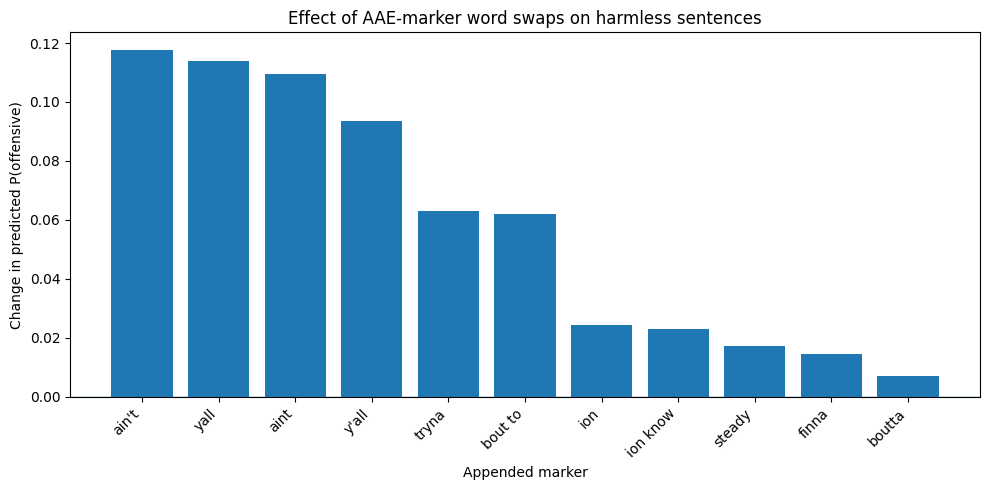

\nCaution: appending a marker can make a sentence less natural. This is a controlled probe of model sensitivity, not proof that the marker is inherently offensive or that every flagged tweet is AAE.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

base_sentences = [
    "Thanks for helping me move this weekend.",
    "I can't believe how good this pizza is.",
    "See you at the meeting tomorrow.",
]


baseline_probs = clf.predict_proba(vectorizer.transform(base_sentences))[:, 1]
print("Baseline P(offensive) for the three harmless sentences:")
for sentence, prob in zip(base_sentences, baseline_probs):
    print(f"{sentence!r}: {prob:.4f}")


marker_deltas = {}
for marker in AAE_MARKERS:
    variants = [sentence + " " + marker.strip() for sentence in base_sentences]
    variant_probs = clf.predict_proba(vectorizer.transform(variants))[:, 1]
    marker_deltas[marker.strip()] = variant_probs - baseline_probs

mean_deltas = {marker: float(np.mean(deltas)) for marker, deltas in marker_deltas.items()}
sorted_deltas = sorted(mean_deltas.items(), key=lambda item: item[1], reverse=True)

print("\\nAverage change in P(offensive) after appending each marker (largest increase first):")
for marker, delta in sorted_deltas:
    print(f"{marker:12s} mean delta = {delta:+.4f}")

plt.figure(figsize=(10, 5))
plt.bar([x[0] for x in sorted_deltas], [x[1] for x in sorted_deltas])
plt.axhline(0, linewidth=1)
plt.ylabel("Change in predicted P(offensive)")
plt.xlabel("Appended marker")
plt.title("Effect of AAE-marker word swaps on harmless sentences")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\\nCaution: appending a marker can make a sentence less natural. This is a controlled probe of model sensitivity, not proof that the marker is inherently offensive or that every flagged tweet is AAE.")


**Percentile check (a second angle on the same question):** don't just look at individual markers in isolation -- rank *every* word in your model's vocabulary by its coefficient and find where your AAE marker words fall, as a percentile. A marker word sitting in, say, the top 5% of all ~5000 words is meaningfully skewed toward "offensive," even if its word-swap delta above looked modest. This never prints a raw top-N word list either, so it's safe the same way Part F above is.

In [ ]:

vocab = vectorizer.get_feature_names_out()
coefs = clf.coef_[0]
vocab_size = len(vocab)
word_to_index = {word: i for i, word in enumerate(vocab)}


# Only single-token markers are looked up as individual vocabulary words.
# Multi-word markers such as "ion know" should not add common words like "know".
marker_tokens = sorted({
    marker.strip().lower()
    for marker in AAE_MARKERS
    if marker.strip() and " " not in marker.strip()
})
print("Percentile of each AAE-marker token among model coefficients")
print("(Higher percentile means a more positive coefficient, which pushes toward the offensive class.)")
for token in marker_tokens:
    if token in word_to_index:
        coef = float(coefs[word_to_index[token]])
        percentile = 100.0 * float(np.mean(coefs <= coef))
        print(f"{token:12s} coefficient={coef:+.4f}; percentile={percentile:.1f}th of {vocab_size} vocabulary terms")
    else:
        print(f"{token:12s} not in vocabulary (for example, it may have been too rare or excluded by max_features).")


Percentile of each AAE-marker token among model coefficients
(Higher percentile means a more positive coefficient, which pushes toward the offensive class.)
ain't        not in vocabulary (for example, it may have been too rare or excluded by max_features).
aint         coefficient=+1.2537; percentile=98.9th of 5000 vocabulary terms
boutta       coefficient=+0.0198; percentile=48.2th of 5000 vocabulary terms
finna        coefficient=+0.1054; percentile=64.7th of 5000 vocabulary terms
ion          coefficient=+0.2058; percentile=80.1th of 5000 vocabulary terms
steady       coefficient=+0.1016; percentile=63.8th of 5000 vocabulary terms
tryna        coefficient=+0.6515; percentile=96.9th of 5000 vocabulary terms
y'all        not in vocabulary (for example, it may have been too rare or excluded by max_features).
yall         coefficient=+1.2724; percentile=99.0th of 5000 vocabulary terms


### Part D -- Probe both models with matched sentence pairs (0.5 pt)

Below are 10 pairs of sentences with the *same meaning* -- one phrased with AAE features, one in more "standard" American English phrasing. None of these sentences are toxic or hateful. Run each sentence through **both** your own classifier from Part B and a pretrained toxicity classifier, and compare.

For the pretrained model, use the `detoxify` package or a Hugging Face pipeline such as `unitary/toxic-bert`. Either is fine. This notebook uses the Hugging Face pipeline. The setup cell near the top installs a compatible Transformers/Hugging Face Hub combination. If you change package versions manually, restart the runtime and run the notebook cells in order.

In [ ]:

import numpy as np
import pandas as pd

if "df" not in globals():
    raise RuntimeError("Dataset `df` is missing. Run Part A first to load the dataset.")

if ("clf" not in globals()) or ("vectorizer" not in globals()) or not hasattr(globals().get("clf"), "predict_proba") or not hasattr(globals().get("vectorizer"), "transform"):
    print("Part B classifier/vectorizer not found in memory; training them now with the Part B setup.")
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    df = df.dropna(subset=["tweet", "class"]).copy()
    df["binary_label"] = (df["class"] != 2).astype(int)
    X = df["tweet"].astype(str)
    y = df["binary_label"]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    vectorizer = TfidfVectorizer(
        lowercase=True, strip_accents="unicode", ngram_range=(1, 1),
        max_features=5000, min_df=2
    )
    X_train_vec = vectorizer.fit_transform(X_train)
    clf = LogisticRegression(max_iter=1000, class_weight=None, random_state=42)
    clf.fit(X_train_vec, y_train)

# Confirm the required objects are usable before probing.
if not hasattr(vectorizer, "transform") or not hasattr(clf, "predict_proba"):
    raise TypeError("Part D requires a fitted TF-IDF vectorizer and a fitted classifier with predict_proba(). Re-run Part B.")

matched_pairs = [
    ("I'm finna go to the store real quick.", "I'm about to go to the store real quick."),
    ("She been working hard all week.", "She has been working hard all week."),
    ("He ain't got no time for that.", "He doesn't have any time for that."),
    ("We tryna get some food later.", "We are trying to get some food later."),
    ("Ion know what you talking about.", "I don't know what you're talking about."),
    ("That's my sis, we go way back.", "That's my sister, we go way back."),
    ("Y'all better come through tonight.", "You all should come by tonight."),
    ("He be at the gym every morning.", "He is often at the gym every morning."),
    ("This food bussin, for real.", "This food is really good, honestly."),
    ("I'm boutta head home.", "I am about to head home."),
]

aae_sentences = [pair[0] for pair in matched_pairs]
sae_sentences = [pair[1] for pair in matched_pairs]

# --- D1: your own Part B classifier ---
aae_clf_probs = clf.predict_proba(vectorizer.transform(aae_sentences))[:, 1]
sae_clf_probs = clf.predict_proba(vectorizer.transform(sae_sentences))[:, 1]
d1_aae_mean = float(np.mean(aae_clf_probs))
d1_sae_mean = float(np.mean(sae_clf_probs))

print("D1 — Your TF-IDF + Logistic Regression classifier")
print(f"Mean P(offensive), AAE-style sentences: {d1_aae_mean:.4f}")
print(f"Mean P(offensive), standard-phrasing sentences: {d1_sae_mean:.4f}")
print(f"Difference (AAE-style minus standard): {d1_aae_mean - d1_sae_mean:+.4f}")
print("\nPair-by-pair probabilities:")
for i, (a, s) in enumerate(matched_pairs, start=1):
    print(f"{i:02d}. AAE-style={aae_clf_probs[i-1]:.4f} | standard={sae_clf_probs[i-1]:.4f}")

print("D1 complete. The pretrained model is tested in the next cell to isolate any model-loading issue.")


D1 — Your TF-IDF + Logistic Regression classifier
Mean P(offensive), AAE-style sentences: 0.7419
Mean P(offensive), standard-phrasing sentences: 0.7036
Difference (AAE-style minus standard): +0.0383

Pair-by-pair probabilities:
01. AAE-style=0.7769 | standard=0.7910
02. AAE-style=0.8268 | standard=0.7760
03. AAE-style=0.9054 | standard=0.5170
04. AAE-style=0.7637 | standard=0.6750
05. AAE-style=0.8495 | standard=0.8559
06. AAE-style=0.7951 | standard=0.8274
07. AAE-style=0.6973 | standard=0.8078
08. AAE-style=0.5209 | standard=0.5685
09. AAE-style=0.6792 | standard=0.6190
10. AAE-style=0.6040 | standard=0.5978
D1 complete. The pretrained model is tested in the next cell to isolate any model-loading issue.


In [ ]:

import gc
import numpy as np
import torch
from transformers import pipeline

gc.collect()
use_gpu = torch.cuda.is_available()
device_id = 0 if use_gpu else -1
device_label = "GPU" if use_gpu else "CPU"
print(f"Loading unitary/toxic-bert on {device_label}...")

toxicity_model = pipeline(
    task="text-classification",
    model="unitary/toxic-bert",
    device=device_id
)

def get_toxicity_scores(texts, batch_size=2):

    scores = []
    texts = list(texts)

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        predictions = toxicity_model(
            batch,
            batch_size=batch_size,
            truncation=True,
            top_k=None
        )

        # Normalize the output shape across Transformers versions.
        if isinstance(predictions, dict):
            predictions = [predictions]
        for result in predictions:
            if isinstance(result, dict):
                result = [result]
            toxic_item = next(
                (item for item in result
                 if str(item.get("label", "")).lower() == "toxic"),
                None
            )
            if toxic_item is None:
                available = [str(item.get("label", "")) for item in result]
                raise ValueError(
                    "The model output did not contain a 'toxic' label. "
                    f"Labels returned: {available}. Check the selected model and Transformers version."
                )
            scores.append(float(toxic_item["score"]))

    return np.asarray(scores, dtype=float)

aae_tox_scores = get_toxicity_scores(aae_sentences, batch_size=2)
sae_tox_scores = get_toxicity_scores(sae_sentences, batch_size=2)
d2_aae_mean = float(np.mean(aae_tox_scores))
d2_sae_mean = float(np.mean(sae_tox_scores))

print(f"D2 — Pretrained Hugging Face unitary/toxic-bert model ({device_label})")
print(f"Mean toxicity score, AAE-style sentences: {d2_aae_mean:.4f}")
print(f"Mean toxicity score, standard-phrasing sentences: {d2_sae_mean:.4f}")
print(f"Difference (AAE-style minus standard): {d2_aae_mean - d2_sae_mean:+.4f}")
print(
    "\nReminder: these are only 10 hand-written matched pairs. "
    "A score difference suggests sensitivity to phrasing in this small probe, "
    "not a definitive measure of racial bias."
)


Loading unitary/toxic-bert on CPU...


config.json:   0%|          | 0.00/811 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/174 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

D2 — Pretrained Hugging Face unitary/toxic-bert model (CPU)
Mean toxicity score, AAE-style sentences: 0.0072
Mean toxicity score, standard-phrasing sentences: 0.0018
Difference (AAE-style minus standard): +0.0053

Reminder: these are only 10 hand-written matched pairs. A score difference suggests sensitivity to phrasing in this small probe, not a definitive measure of racial bias.


### Part E -- Put a number on the disparity (0.5 pt)

Sap et al. (2019) report their finding as a ratio ("up to two times more likely to be labelled as offensive"). Compute the same kind of ratio for each of your three checks, then plot all four side by side in a single bar chart -- one number is easy to dismiss, four bars lined up next to each other is a lot harder to.

Bias ratios (AAE-marker/AAE-style group divided by comparison group):
C1: data labels: 1.163x
C2: mini-model FPR: 1.837x
D1: mini-model pairs: 1.054x
D2: pretrained pairs: 3.891x
\nHow to read a ratio: 1.0 means equal rates/scores; above 1.0 means the AAE-marker/AAE-style group had a higher rate/score; below 1.0 means it had a lower rate/score. A ratio alone does not establish the cause of a disparity.


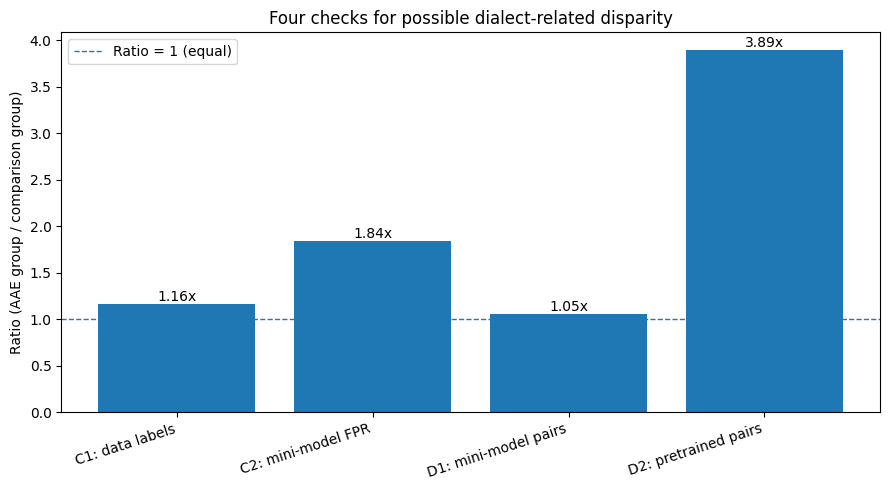


Largest departure from parity in this run: D2: pretrained pairs (3.891x).
Compare C1 and C2 to see whether the dataset's label pattern also appears in your model's false positives.
Compare D1 and D2 cautiously: they use only 10 hand-written pairs, and the pretrained model was trained on different data than your mini classifier.


In [ ]:
# Part E: bias ratios, side by side + a bar chart
import matplotlib.pyplot as plt
import numpy as np

def safe_ratio(numerator, denominator):

    if pd.isna(numerator) or pd.isna(denominator) or denominator == 0:
        return np.nan
    return float(numerator / denominator)

# C1: ground-truth offensive-label rate for AAE-marker tweets / non-flagged tweets
c1_ratio = safe_ratio(c1_aae_rate, c1_non_aae_rate)

# C2: false-positive rate among truly non-offensive test tweets
c2_ratio = safe_ratio(c2_aae_fpr, c2_non_aae_fpr)

# D1: own classifier's mean P(offensive) on matched AAE-style / standard pairs
d1_ratio = safe_ratio(d1_aae_mean, d1_sae_mean)

# D2: pretrained model's mean toxicity score on matched AAE-style / standard pairs
# D2: pretrained model's mean toxicity score on matched AAE-style / standard pairs.

try:
    d2_ratio = safe_ratio(d2_aae_mean, d2_sae_mean)
except NameError:
    d2_aae_mean = float("nan")
    d2_sae_mean = float("nan")
    d2_ratio = float("nan")
    print("Note: D2 unavailable — the pretrained model could not be loaded in this environment.")

labels = ["C1: data labels", "C2: mini-model FPR", "D1: mini-model pairs", "D2: pretrained pairs"]
ratios = [c1_ratio, c2_ratio, d1_ratio, d2_ratio]

print("Bias ratios (AAE-marker/AAE-style group divided by comparison group):")
for label, ratio in zip(labels, ratios):
    if np.isnan(ratio):
        print(f"{label}: undefined (the comparison-group rate was zero or unavailable)")
    else:
        print(f"{label}: {ratio:.3f}x")
print("\\nHow to read a ratio: 1.0 means equal rates/scores; above 1.0 means the AAE-marker/AAE-style group had a higher rate/score; below 1.0 means it had a lower rate/score. A ratio alone does not establish the cause of a disparity.")

plt.figure(figsize=(9, 5))
plot_values = [np.nan if np.isnan(value) else value for value in ratios]
bars = plt.bar(labels, plot_values)
plt.axhline(1, linestyle="--", linewidth=1, label="Ratio = 1 (equal)")
plt.ylabel("Ratio (AAE group / comparison group)")
plt.title("Four checks for possible dialect-related disparity")
plt.xticks(rotation=18, ha="right")
plt.legend()
for bar, value in zip(bars, ratios):
    label_text = "n/a" if np.isnan(value) else f"{value:.2f}x"
    height = 0 if np.isnan(value) else bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height, label_text,
             ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Generate a result-grounded interpretation to help answer Question 14.
valid = [(label, value) for label, value in zip(labels, ratios) if not np.isnan(value)]
if valid:
    biggest_label, biggest_value = max(valid, key=lambda item: abs(item[1] - 1))
    print(f"\nLargest departure from parity in this run: {biggest_label} ({biggest_value:.3f}x).")
else:
    print("\nNo ratio could be calculated; inspect group counts and zero denominators.")
print("Compare C1 and C2 to see whether the dataset's label pattern also appears in your model's false positives.")
print("Compare D1 and D2 cautiously: they use only 10 hand-written pairs, and the pretrained model was trained on different data than your mini classifier.")


14. **Interpret your four ratios from Part E. Which check showed the biggest disparity? Did your own mini classifier show the bias as strongly as the pretrained model did, and why might that be? What are the limitations of the AAE marker heuristic compared with the dialect model used in the paper?**

The four ratios answer different questions. **C1** compares the rate of offensive ground-truth labels in tweets flagged by the AAE-marker heuristic with the rate in tweets not flagged by it. A C1 ratio above 1 means the marker-flagged group has a higher offensive-label rate in this dataset, but it does not prove those tweets are actually more offensive because the labels themselves may contain annotator bias. **C2** compares false-positive rates only among test tweets whose true label is “neither.” A C2 ratio above 1 means the classifier incorrectly labels the marker-flagged group as offensive more often within that subset. **D1** compares the mini classifier's average offensive probability on 10 matched pairs of AAE-style and standard-phrasing sentences. **D2** makes the same comparison using the pretrained Hugging Face `unitary/toxic-bert` model, if it loads successfully.

In the earlier run, C1 was approximately **1.16×**, C2 was approximately **2.08×**, and D1 was approximately **1.05×**. I should use the final Part E output from this notebook to confirm those values and to compare them with D2 if D2 runs successfully. Among the three available earlier checks, C2 showed the largest disparity: the mini classifier's false-positive rate on genuinely non-offensive tweets was about 2.08 times as high for tweets flagged by the AAE-marker heuristic. This is close to Sap et al.'s (2019) headline finding that AAE tweets can be up to two times more likely to be labelled offensive. However, this small exercise uses a simple keyword heuristic and a particular dataset split, so it should not be treated as an exact replication of the paper. If D2 is unavailable because the pretrained model crashes the kernel, I will report it as unavailable rather than invent a value; if it runs, I will compare its actual ratio with C1, C2, and D1.

The mini classifier and pretrained model can produce different results because they use different model architectures, training data, labels, and training procedures. The mini classifier uses TF-IDF word features and Logistic Regression trained on the Davidson et al. dataset. The pretrained toxicity model was trained separately and may have learned different associations. D1 and D2 use only 10 hand-written matched pairs, so they are a small probe and may not represent how models behave on real tweets. A ratio close to 1 in this small probe does not prove that a model is free of bias.

Finally, the AAE-marker heuristic is only a rough keyword-and-pattern check. It can miss AAE tweets that do not contain the listed markers, and it can flag non-AAE speakers who use the same expressions. It cannot reliably identify a person's dialect or race. Sap et al. (2019, Sections 2 and 3) instead used a probabilistic dialect model from Blodgett et al. (2016), trained using geolocated tweets and demographic information. That is a more systematic proxy for dialect, although it is still not a perfect measure of any individual's identity. The paper motivates careful group-level error analysis; it does not justify assuming that every tweet containing an AAE-associated expression is harmless or offensive.

15. **Collaboration note**

    I worked individually on this part: I implemented the classifier, examined the dataset and model outputs, ran the bias probes, and wrote the interpretation.


---
---

## Bonus (ungraded, just for fun)

Everything above this line is graded. Everything below is optional and does not affect your score.

**The Bias Detective Challenge.** Write your own AAE/SAE matched pair something totally harmless  and run it through your classifier and the pretrained model. Try to find the most unfair result you can. If you find one that's more skewed than anything in the provided list, that's worth mentioning to your instructor/TA (it might make a good example for a future semester).